# 2026/10/21：画像反復と回転拡張による学習効果の比較

教授のFB「復元誤差が減ったのは、回転の効果か、それとも学習量が増えたためか？」を調べるための学習コードです。

| 条件 | 1エポックに使う画像 | 目的 |
|---|---|---|
| A_original | 元画像209枚 | 基準 |
| B_repeat10 | 同じ元画像を、回転せず10回ずつ使用（延べ2,090枚） | 反復・更新回数が増えた影響 |
| C_rotate10 | 同じ元画像を0〜324度、36度刻みの10方向へ回転（2,090枚） | Bと比べた回転拡張の影響 |

- 土台は過去の回転実験と同じ **Hybrid CNN＋FC VAE**。新しいモデルを同じ初期重みから学習します。
- BとCは元画像の対応・シャッフル順・初期重み・乱数・更新回数・βの変化を揃えます。
- AとBは100エポックでも更新回数が異なります。A対Bは純粋な「枚数だけ」の実験ではなく、反復・更新回数・更新に対するβの進み方を含む比較です。
- Cは820×820で回転してから128×128へ縮小します。過去の「縮小後に回転」とは異なる条件です。
- 画像はメモリ内で生成し、元画像・過去の拡張画像・既存モデルは変更しません。
- 学習時の誤差と、全条件共通の正常テスト画像20枚での復元誤差を区別します。
- このノートブックは復元挙動を調べるものです。異常検知の性能比較には引き続きAUROCを用い、その評価は別途行います。

**初期設定では少量の動作確認だけが実行され、正式学習は始まりません。**
正式学習を始める場合は、設定セルの RUN_FULL_TRAINING を True にして、上から順に実行してください。

In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

from pathlib import Path
from io import BytesIO
from datetime import datetime
from zoneinfo import ZoneInfo
import copy
import hashlib
import importlib.metadata
import json
import math
import platform
import random
import time
import uuid

import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

%matplotlib inline

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'code' / '260718拡張データによる学習.ipynb').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('このリポジトリ内を作業ディレクトリにしてください。')

TRAIN_DIR = ROOT / 'data/bottle/train/good'
NORMAL_TEST_DIR = ROOT / 'data/bottle/test/good'
OUTPUT_BASE = ROOT / 'saved_models/rotation_control_20261021'
RUN_FULL_TRAINING = False
RUN_SMOKE_TEST = True

SEEDS = [42]  # 複数シードで調べる場合は例：[42, 43, 44]。各シードでA/B/Cを実行。
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
LATENT_DIM = 64
ANNEALING_EPOCHS = 50
ANGLES = tuple(range(0, 360, 36))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 0  # Notebook/Windowsで確実に実行し、B/Cの順序を保つ。
CONDITIONS = ('A_original', 'B_repeat10', 'C_rotate10')
CONDITION_LABELS = {'A_original': 'A：元画像', 'B_repeat10': 'B：10回反復', 'C_rotate10': 'C：10方向回転'}

assert len(SEEDS) > 0 and len(set(SEEDS)) == len(SEEDS)
assert EPOCHS > 0 and BATCH_SIZE >= 2 and ANNEALING_EPOCHS > 0
assert ANGLES == (0, 36, 72, 108, 144, 180, 216, 252, 288, 324)
torch.set_num_threads(min(4, max(1, torch.get_num_threads())))
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

available_fonts = {f.name for f in font_manager.fontManager.ttflist}
for font in ['Yu Gothic', 'Meiryo', 'MS Gothic', 'Noto Sans CJK JP', 'IPAexGothic']:
    if font in available_fonts:
        plt.rcParams['font.family'] = font
        break
else:
    import japanize_matplotlib
plt.rcParams.update({'font.size': 11, 'axes.unicode_minus': False, 'figure.dpi': 100})
print(f'デバイス：{DEVICE} / 正式学習：{RUN_FULL_TRAINING} / seeds：{SEEDS}')

デバイス：cpu / 正式学習：False / seeds：[42]


## 1. 元画像と共通の正常テスト画像を読み込む

元画像からRGBのまま中央820×820を切り出し、回転用の高解像度画像をメモリ内に保持します。

| 対象 | 処理順 |
|---|---|
| A・B・共通正常テスト | 中央820×820 → LANCZOSで128×128へ縮小 → グレースケール化 → 0〜1 |
| C | 中央820×820 → この解像度で回転 → LANCZOSで128×128へ縮小 → グレースケール化 → 0〜1 |

回転は最近傍補間・白埋め・サイズ維持です。補間方式を変えずに、縮小と回転の順序を変更します。Cの0度画像には回転処理を加えず、A・Bと同じ入力を使います。

**過去の実験は128×128へ縮小した後に回転しており、今回のCは異なる前処理条件です。** 高解像度で回転してから縮小することでギザギザを抑えることを狙いますが、画素の変化そのものがなくなるわけではありません。

元画像のIDと回転番号は順序確認用の記録だけに使い、モデルに入力するのは画像テンソルのみです。モデルに「同じ元画像のグループ」と教える処理ではありません。


In [2]:
# RGBの820×820画像を保持し、Cだけ縮小前に回転する。
crop_transform = transforms.CenterCrop(820)
final_transform = transforms.Compose([
    transforms.Resize((128, 128), interpolation=transforms.InterpolationMode.LANCZOS),
    transforms.Grayscale(num_output_channels=1),
])
# A/Bと共通テストの処理は従来と同じ順序。
base_transform = transforms.Compose([crop_transform, final_transform])
to_tensor = transforms.ToTensor()

def read_base_images(directory):
    paths = sorted(directory.glob('*.png'), key=lambda p: p.name)
    if not paths:
        raise FileNotFoundError(f'画像がありません：{directory}')
    images, manifest = [], []
    for path in paths:
        raw = path.read_bytes()
        with Image.open(BytesIO(raw)) as im:
            image = crop_transform(im.convert('RGB'))
        tensor = to_tensor(final_transform(image))
        images.append(image.copy())
        manifest.append({
            'path': path.relative_to(ROOT).as_posix(),
            'file_sha256': hashlib.sha256(raw).hexdigest(),
            'preprocessed_sha256': hashlib.sha256(tensor.numpy().tobytes()).hexdigest(),
        })
    return images, manifest

class RotationControlDataset(Dataset):
    def __init__(self, base_images, condition):
        if condition not in CONDITIONS:
            raise ValueError(condition)
        self.condition = condition
        self.base_images = base_images
        self.base_tensors = torch.stack([to_tensor(final_transform(im)) for im in base_images])
        self.repeats = 1 if condition == 'A_original' else len(ANGLES)
        self.rotated_tensors = None
        if condition == 'C_rotate10':
            variants = []
            for image in base_images:
                for angle in ANGLES:
                    variant = image if angle == 0 else TF.rotate(
                        image, angle=angle,
                        interpolation=transforms.InterpolationMode.NEAREST,
                        expand=False, fill=255,
                    )
                    # 820×820で回転してから、全条件共通の縮小・グレースケール化。
                    variants.append(to_tensor(final_transform(variant)))
            self.rotated_tensors = torch.stack(variants)

    def __len__(self):
        return len(self.base_images) * self.repeats

    def __getitem__(self, index):
        parent, variant = divmod(index, self.repeats)
        image = self.rotated_tensors[index] if self.rotated_tensors is not None else self.base_tensors[parent]
        # parent/variantは記録用。ネットワークに渡すのはimageのみ。
        return image, parent, variant

def loader_for(dataset, seed, batch_size=BATCH_SIZE):
    if len(dataset) % batch_size == 1:
        raise ValueError('最終バッチが1枚になりBatchNormが使えません。バッチサイズを調整してください。')
    generator = torch.Generator().manual_seed(int(seed) + 1000)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True,
                      generator=generator, drop_last=False, num_workers=NUM_WORKERS)

train_images, train_manifest = read_base_images(TRAIN_DIR)
normal_test_images, normal_test_manifest = read_base_images(NORMAL_TEST_DIR)
if len(train_images) != 209 or len(normal_test_images) != 20:
    raise ValueError('計画時の209枚・20枚と異なります。データ変更を確認してから設定を見直してください。')
# 完全一致の前処理画像が学習・評価に混ざっていないかを確認。
train_hashes = {v['preprocessed_sha256'] for v in train_manifest}
test_hashes = {v['preprocessed_sha256'] for v in normal_test_manifest}
if train_hashes & test_hashes:
    raise ValueError('学習画像と共通テスト画像に、前処理後の完全一致が見つかりました。')
datasets = {name: RotationControlDataset(train_images, name) for name in CONDITIONS}
normal_test_tensor = torch.stack([to_tensor(final_transform(im)) for im in normal_test_images])

assert len(datasets['A_original']) == 209
assert len(datasets['B_repeat10']) == len(datasets['C_rotate10']) == 2090
for parent in range(len(train_images)):
    assert torch.equal(datasets['A_original'][parent][0], datasets['B_repeat10'][parent * 10][0])
    assert torch.equal(datasets['B_repeat10'][parent * 10][0], datasets['C_rotate10'][parent * 10][0])

condition_table = pd.DataFrame([{
    '条件': CONDITION_LABELS[name], '元画像数': len(train_images),
    '1エポックの延べ枚数': len(dataset),
    '更新回数/エポック': math.ceil(len(dataset) / BATCH_SIZE),
    'エポック数': EPOCHS,
    '総更新回数': EPOCHS * math.ceil(len(dataset) / BATCH_SIZE),
} for name, dataset in datasets.items()])
display(condition_table)
print('共通の正常テスト画像：20枚。学習やモデル選択には使用しません。')

,条件,元画像数,1エポックの延べ枚数,更新回数/エポック,エポック数,総更新回数
0,A：元画像,209,209,7,100,700
1,B：10回反復,209,2090,66,100,6600
2,C：10方向回転,209,2090,66,100,6600


共通の正常テスト画像：20枚。学習やモデル選択には使用しません。


## 2. A・B・Cの画像を確認する

同じ元画像から作った例を表示します。Bは10枚とも同一画像で、Cは向きが変わります。円形でも模様や陰影の画素位置は変わります。

Cの各画像は820×820で回転した後、128×128へ縮小しています。

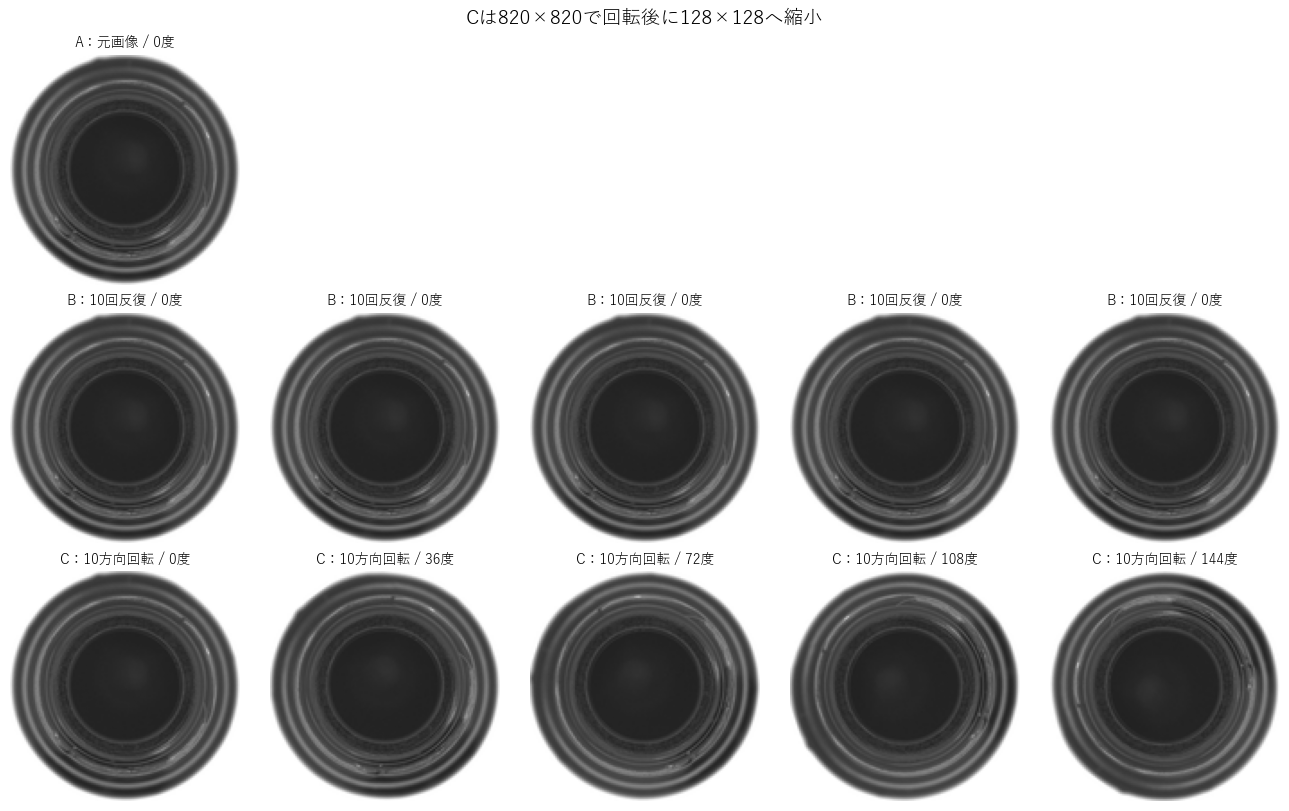

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(13, 8), constrained_layout=True)
for row, condition in enumerate(CONDITIONS):
    for column in range(5):
        if condition == 'A_original' and column > 0:
            axes[row, column].set_visible(False)
            continue
        index = 0 if condition == 'A_original' else column
        image, parent, variant = datasets[condition][index]
        axes[row, column].imshow(image[0], cmap='gray', vmin=0, vmax=1)
        angle = ANGLES[variant] if condition == 'C_rotate10' else 0
        axes[row, column].set_title(f'{CONDITION_LABELS[condition]} / {angle}度', fontsize=10)
        axes[row, column].axis('off')
fig.suptitle('Cは820×820で回転後に128×128へ縮小', fontsize=14)
plt.show()
plt.close(fig)

## 3. モデルと損失関数

過去のHybridモデルと同じ構造です。学習時の損失は「画素二乗誤差の合計＋β×KL項」、学習時の潜在変数はサンプリングします。

共通の正常画像20枚の評価では、全条件とも潜在変数の平均を使います。評価の乱数を除いて復元を比較するためであり、学習中に記録するサンプリング復元の誤差とは別の値です。

In [4]:
class VAE_Hybrid_CNN_FC(nn.Module):
    def __init__(self, latent_dim=64):
        super(VAE_Hybrid_CNN_FC, self).__init__()

        # -------------------------------------------------------------
        # 【エンコーダ前半】 CNN_Deep5（空間圧縮: 128x128 -> 4x4）
        # -------------------------------------------------------------
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(256), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【エンコーダ後半】 FC_Only（段階的圧縮: 4096次元 -> 128次元）
        # -------------------------------------------------------------
        self.encoder_fc = nn.Sequential(
            nn.Linear(256 * 4 * 4, 1024), nn.ReLU(),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )

        # 潜在空間へのマッピング（128次元 -> 64次元）
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # -------------------------------------------------------------
        # 【デコーダ前半】 FC_Only（段階的復元: 64次元 -> 4096次元）
        # -------------------------------------------------------------
        self.decoder_fc = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 1024), nn.ReLU(),
            # ※CNNへ繋ぐため、最後はSigmoidではなくReLUを使用します
            nn.Linear(1024, 256 * 4 * 4), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【デコーダ後半】 CNN_Deep5（空間復元: 4x4 -> 128x128）
        # -------------------------------------------------------------
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x, sample=True):
        # 1. CNNによる特徴抽出
        h = self.encoder_conv(x)
        h = torch.flatten(h, start_dim=1)

        # 2. FCによる段階的圧縮
        h = self.encoder_fc(h)

        # 3. 潜在変数の計算と安全装置（クランプ）
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)

        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std if sample else mu

        # 4. FCによる段階的復元
        h_recon = self.decoder_fc(z)
        h_recon = h_recon.view(-1, 256, 4, 4) # 4階テンソルに戻す

        # 5. CNNによる画像復元
        recon = self.decoder_conv(h_recon)

        return recon, mu, logvar

def vae_loss(recon_x, x, mu, logvar, beta=1.0):  
    MSE = nn.functional.mse_loss(recon_x, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return MSE, KLD, MSE + beta * KLD

def seed_everything(seed):
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))

def copy_cpu_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

def state_digest(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        tensor = state[name].detach().cpu().contiguous()
        digest.update(name.encode('utf-8') + str(tensor.dtype).encode('ascii'))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()

def make_initial_state(seed):
    seed_everything(seed)
    initial_model = VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM)
    return copy_cpu_state(initial_model)

def new_model(initial_state, seed, device=DEVICE):
    model = VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM).to(device)
    model.load_state_dict(initial_state, strict=True)
    # モデル構築で消費された乱数を戻し、各条件のサンプリング列を揃える。
    seed_everything(seed)
    return model

## 4. 学習・共通正常画像の評価・保存用関数

- βは過去と同じく、0始まりのエポック番号÷50（上限1）。第1エポックは0、第51エポックで1になります。
- 学習誤差は各条件の学習画像上の「1画像あたりの二乗誤差の合計」。共通テスト画像の復元誤差と区別して記録します。
- B/Cは同じシードの別々のDataLoaderを作り、対応する元画像が同じ順序で入力されます。入力順のハッシュでも確認します。
- 同じシード内では、全条件を同じ初期重みから始めます。初期重みは過去の学習済み重みではありません。
- 正式実行時にのみ、実行固有の新規フォルダを作成します。既存の重みを上書きしません。

In [5]:
def train_epoch(model, loader, optimizer, beta, device, order_digest, max_batches=None):
    model.train()
    sums = np.zeros(3, dtype=np.float64)
    seen, updates = 0, 0
    for images, parents, variants in loader:
        if max_batches is not None and updates >= max_batches:
            break
        pair_order = torch.stack([parents, variants], dim=1).numpy().astype('<i8', copy=False)
        order_digest.update(pair_order.tobytes())
        images = images.to(device)
        optimizer.zero_grad(set_to_none=True)
        reconstruction, mu, logvar = model(images, sample=True)
        mse, kld, loss = vae_loss(reconstruction, images, mu, logvar, beta=beta)
        if not all(torch.isfinite(value).item() for value in [mse, kld, loss]):
            raise FloatingPointError('損失にNaN/infが発生しました。')
        loss.backward()
        if any(p.grad is not None and not torch.isfinite(p.grad).all().item() for p in model.parameters()):
            raise FloatingPointError('勾配にNaN/infが発生しました。')
        optimizer.step()
        sums += [mse.item(), kld.item(), loss.item()]
        seen += len(images)
        updates += 1
    if not seen:
        raise ValueError('学習バッチがありません。')
    return {'train_sse_per_image': float(sums[0] / seen),
            'train_kl_per_image': float(sums[1] / seen),
            'train_total_per_image': float(sums[2] / seen),
            'seen_images': seen, 'updates': updates}

def evaluate_normal(model, images, names, device=DEVICE):
    model.eval()
    rows = []
    with torch.inference_mode():
        for start in range(0, len(images), BATCH_SIZE):
            inputs = images[start:start + BATCH_SIZE].to(device)
            reconstruction, _, _ = model(inputs, sample=False)
            per_image = (inputs - reconstruction).square().flatten(1).sum(1).cpu().numpy()
            if not np.isfinite(per_image).all():
                raise FloatingPointError('評価誤差にNaN/infが発生しました。')
            for name, error in zip(names[start:start + BATCH_SIZE], per_image):
                rows.append({'path': name, 'sse_per_image': float(error),
                             'mse_per_pixel': float(error / (128 * 128))})
    return pd.DataFrame(rows)

def write_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

def train_condition(condition, seed, initial_state, directory):
    directory.mkdir(parents=True, exist_ok=False)
    dataset = datasets[condition]
    loader = loader_for(dataset, seed)
    model = new_model(initial_state, seed)
    initial_hash = state_digest(copy_cpu_state(model))
    if initial_hash != state_digest(initial_state):
        raise AssertionError('初期重みが一致しません。')
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    order_digest = hashlib.sha256()
    history = []
    total_updates = 0
    started = time.perf_counter()
    for epoch in range(EPOCHS):
        beta = min(1.0, epoch / ANNEALING_EPOCHS)
        values = train_epoch(model, loader, optimizer, beta, DEVICE, order_digest)
        assert values['seen_images'] == len(dataset) and values['updates'] == len(loader)
        total_updates += values['updates']
        history.append({'epoch': epoch + 1, 'beta': beta,
                        'cumulative_updates': total_updates, **values})
        pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
        if epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == EPOCHS:
            print(f'{condition} / seed={seed} / epoch={epoch + 1:3d}/{EPOCHS} '
                  f'/ beta={beta:.2f} / train SSE={values["train_sse_per_image"]:.4f} '
                  f'/ updates={total_updates}', flush=True)

    assert total_updates == EPOCHS * math.ceil(len(dataset) / BATCH_SIZE)
    # エポック選択はせず、固定した最終エポックだけを共通テストで確認する。
    normal_results = evaluate_normal(model, normal_test_tensor,
                                     [r['path'] for r in normal_test_manifest])
    normal_results.to_csv(directory / 'normal_test_errors.csv', index=False)
    torch.save(copy_cpu_state(model), directory / 'model_final.pth')
    history_frame = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(12, 7))
    for column, label, style in [
        ('train_total_per_image', 'Total Loss', '-'),
        ('train_sse_per_image', 'Reconstruction SSE', '--'),
        ('train_kl_per_image', 'KL', '-.'),
    ]:
        ax.plot(history_frame.epoch, np.maximum(history_frame[column], 1e-12),
                linestyle=style, label=label)
    ax.set(xlabel='エポック', ylabel='1画像あたりの損失', yscale='log')
    ax.set_title(f'{CONDITION_LABELS[condition]} / seed={seed}', fontsize=16)
    ax.grid(True, which='both', linestyle='--', alpha=0.7)
    ax.legend()
    fig.tight_layout()
    fig.savefig(directory / 'learning_curve.png', dpi=150)
    plt.close(fig)
    summary = {
        'condition': condition, 'seed': int(seed), 'epochs': EPOCHS,
        'images_per_epoch': len(dataset), 'updates': total_updates,
        'initial_state_sha256': initial_hash,
        'sample_order_sha256': order_digest.hexdigest(),
        'final_train_sse_per_image': history[-1]['train_sse_per_image'],
        'normal_test_sse_per_image': float(normal_results.sse_per_image.mean()),
        'normal_test_mse_per_pixel': float(normal_results.mse_per_pixel.mean()),
        'normal_test_inference': 'posterior mean, no sampling',
        'seconds': time.perf_counter() - started,
    }
    write_json(directory / 'summary.json', summary)
    del optimizer, model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return summary

## 5. 少量データでの動作確認（正式な実験結果ではない）

元画像の一部（Aは先頭4枚、B/Cは先頭2枚から作った画像）を使い、各条件を2バッチだけ更新します。CPU・少量データで入出力、損失、勾配、順序、初期重み、平均推論を確認します。

この動作確認の重み・ログはファイル保存せず、正式学習には引き継ぎません。以下の値は性能比較に使いません。

In [6]:
smoke_report = []
if RUN_SMOKE_TEST:
    smoke_seed = 123
    smoke_sets = {name: RotationControlDataset(train_images[:2], name) for name in CONDITIONS}
    # Aも2バッチ実行できるよう、動作確認に限り元画像を4枚使う。
    smoke_sets['A_original'] = RotationControlDataset(train_images[:4], 'A_original')
    initial = make_initial_state(smoke_seed)
    initial_hash = state_digest(initial)
    for name in CONDITIONS:
        ds = smoke_sets[name]
        batch = 2 if name == 'A_original' else 4
        loader = loader_for(ds, smoke_seed, batch_size=batch)
        model = new_model(initial, smoke_seed, device=torch.device('cpu'))
        assert state_digest(copy_cpu_state(model)) == initial_hash
        optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
        digest = hashlib.sha256()
        metrics = train_epoch(model, loader, optimizer, beta=0.0,
                              device=torch.device('cpu'), order_digest=digest, max_batches=2)
        assert metrics['updates'] == 2
        check = evaluate_normal(model, normal_test_tensor[:2],
                                [r['path'] for r in normal_test_manifest[:2]], device=torch.device('cpu'))
        assert len(check) == 2 and np.isfinite(check.sse_per_image).all()
        smoke_report.append({'condition': name, 'updates': metrics['updates'],
                             'initial_state_sha256': initial_hash,
                             'sample_order_sha256': digest.hexdigest(),
                             'status': '動作確認のみ：正常終了'})
        del model, optimizer
    assert smoke_report[1]['sample_order_sha256'] == smoke_report[2]['sample_order_sha256']
    assert len({v['initial_state_sha256'] for v in smoke_report}) == 1
    display(pd.DataFrame(smoke_report)[['condition', 'updates', 'status']])
    print('B/Cの同一順序、全条件の同一初期重み、有限な損失・勾配・平均推論を確認。正式学習は未実施。')
    del initial, smoke_sets
else:
    print('動作確認はスキップしました。')

,condition,updates,status
0,A_original,2,動作確認のみ：正常終了
1,B_repeat10,2,動作確認のみ：正常終了
2,C_rotate10,2,動作確認のみ：正常終了


B/Cの同一順序、全条件の同一初期重み、有限な損失・勾配・平均推論を確認。正式学習は未実施。


## 6. 正式学習の開始

設定セルで RUN_FULL_TRAINING=True にして上から実行すると、設定した各シードでA→B→Cの順に学習します。

保存先：saved_models/rotation_control_20261021/日時と実行ID/seed_番号/条件名/

- 実行全体：設定、元画像と共通テスト画像のハッシュ一覧、条件表、結果の比較表。
- 条件ごと：毎エポックのhistory.csv、最終重みmodel_final.pth、学習曲線、共通正常画像20枚の誤差、summary.json。
- 同じセルを再実行すると別の新規フォルダに保存します。既存の実験結果は上書きしません。
- 正常テスト20枚は最終結果の確認専用。学習、早期終了、エポック選択、設定の調整には使いません。
- 1シードは予備的な比較です。効果を判断する際は、事前に決めた複数シードでの確認も検討してください。

In [7]:
run_dir = None
comparison_results = []
if RUN_FULL_TRAINING:
    run_id = datetime.now(ZoneInfo('Asia/Tokyo')).strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:8]
    run_dir = OUTPUT_BASE / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    versions = {package: importlib.metadata.version(package)
                for package in ['torch', 'torchvision', 'numpy', 'Pillow']}
    config = {
        'experiment': 'rotation_control_20261021_highres_rotation', 'run_id': run_id,
        'seeds': SEEDS, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
        'optimizer': 'Adam', 'learning_rate': LEARNING_RATE,
        'latent_dim': LATENT_DIM, 'annealing_epochs': ANNEALING_EPOCHS,
        'beta_rule': 'min(1.0, zero_based_epoch / annealing_epochs)',
        'angles': list(ANGLES), 'rotation_interpolation': 'NEAREST',
        'rotation_fill': 255, 'rotation_expand': False,
        'rotation_stage': 'after_center_crop_before_resize',
        'rotation_input_size': [820, 820], 'network_input_size': [128, 128],
        'preprocessing': 'CenterCrop820 RGB, optional rotation at820, Resize128 LANCZOS, Grayscale, ToTensor',
        'preprocessing_by_condition': {
            'A_original': 'CenterCrop820 RGB -> Resize128 LANCZOS -> Grayscale -> ToTensor',
            'B_repeat10': 'CenterCrop820 RGB -> no rotation -> Resize128 LANCZOS -> Grayscale -> ToTensor',
            'C_rotate10': 'CenterCrop820 RGB -> Rotate NEAREST at820 (skip0) -> Resize128 LANCZOS -> Grayscale -> ToTensor',
        },
        'training_loss': 'sum pixel squared error + beta * sum standard-normal KL',
        'training_inference': 'posterior sampling',
        'normal_test_inference': 'posterior mean',
        'device': str(DEVICE), 'python': platform.python_version(), 'versions': versions,
        'torch_threads': torch.get_num_threads(),
        'status': 'running',
    }
    write_json(run_dir / 'config.json', config)
    write_json(run_dir / 'train_manifest.json', train_manifest)
    write_json(run_dir / 'normal_test_manifest.json', normal_test_manifest)
    condition_table.to_csv(run_dir / 'conditions.csv', index=False)
    try:
        for seed in SEEDS:
            initial = make_initial_state(seed)
            summaries = []
            for name in CONDITIONS:
                summary = train_condition(name, seed, initial, run_dir / f'seed_{seed}' / name)
                summaries.append(summary)
                comparison_results.append(summary)
                pd.DataFrame(comparison_results).to_csv(run_dir / 'comparison.csv', index=False)
            assert len({v['initial_state_sha256'] for v in summaries}) == 1
            assert summaries[1]['updates'] == summaries[2]['updates']
            assert summaries[1]['sample_order_sha256'] == summaries[2]['sample_order_sha256']
            del initial
        config['status'] = 'completed'
        write_json(run_dir / 'config.json', config)
        print(f'正式学習と共通正常画像の評価が完了：{run_dir}')
    except BaseException as exc:
        config['status'] = 'interrupted_or_failed'
        config['error'] = f'{type(exc).__name__}: {exc}'
        write_json(run_dir / 'config.json', config)
        raise
else:
    print('RUN_FULL_TRAINING=False：3条件×100エポックの正式学習は実行していません。')
    print('正式学習を行う場合は設定をTrueにして、上から実行してください。')

RUN_FULL_TRAINING=False：3条件×100エポックの正式学習は実行していません。
正式学習を行う場合は設定をTrueにして、上から実行してください。


## 7. 学習後の結果表示

左図は各条件の学習データ上の誤差です。条件間で画像が異なるため、この値だけで一般化性能を判断しません。

右図は全条件で同じ正常画像20枚に対する平均推論の誤差で、復元性能を比較するための補助情報です。異常検知の精度そのものではありません。表には更新回数も表示します。

In [8]:
if comparison_results:
    comparison_frame = pd.DataFrame(comparison_results)
    display(comparison_frame[[
        'condition', 'seed', 'updates', 'final_train_sse_per_image',
        'normal_test_sse_per_image', 'normal_test_mse_per_pixel',
    ]])
    colors = {'A_original': '#526b8e', 'B_repeat10': '#6f8a64', 'C_rotate10': '#b27b35'}
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    for seed in SEEDS:
        for name in CONDITIONS:
            frame = pd.read_csv(run_dir / f'seed_{seed}' / name / 'history.csv')
            axes[0].plot(frame.epoch, frame.train_sse_per_image,
                         label=f'{CONDITION_LABELS[name]} / seed={seed}', color=colors[name], alpha=0.8)
    axes[0].set(xlabel='エポック', ylabel='1画像あたりの二乗誤差の合計',
                yscale='log', title='学習時：各条件の学習画像上の復元誤差')
    positions = np.arange(len(CONDITIONS))
    for name, position in zip(CONDITIONS, positions):
        values = comparison_frame.loc[comparison_frame.condition == name, 'normal_test_sse_per_image']
        axes[1].scatter(np.full(len(values), position), values, color=colors[name], s=55)
        axes[1].plot([position - 0.16, position + 0.16], [values.mean(), values.mean()],
                     color=colors[name], linewidth=3)
    axes[1].set_xticks(positions, [CONDITION_LABELS[name] for name in CONDITIONS])
    axes[1].set(ylabel='1画像あたりの二乗誤差の合計',
                title='評価時：共通の正常20枚（平均推論）')
    axes[0].legend(fontsize=8)
    for ax in axes:
        ax.grid(True, linestyle='--', alpha=0.35)
    fig.savefig(run_dir / 'comparison.png', dpi=150)
    plt.show()
    plt.close(fig)
else:
    print('正式学習が未実施のため、比較結果の表・学習曲線はまだありません。')

正式学習が未実施のため、比較結果の表・学習曲線はまだありません。


## 解釈するときに確認すること

- A対B：反復、更新回数、更新に対するβの進み方が増えた影響を含みます。「独立な新しい画像を増やした効果」ではありません。
- B対C：延べ枚数、更新回数、元画像の入力順、β、初期重みを揃えたうえで、回転を加える影響を調べます。回転は820×820で行い、最後に128×128へ縮小します。補間・白埋め・画像端の切り取りも今回の回転操作の一部です。過去の縮小後回転をそのまま再現した実験とは区別します。
- 回転前後が同じ潜在表現になることや、モデルが元画像の関連性を認識したことを、この比較だけで証明することはできません。
- 丸ではない対象に適切かどうかは、その対象で回転しても正常の意味が保たれるかを別途考える必要があります。
- 共通テスト画像の復元誤差とAUROCは別の指標です。復元誤差が改善しても、異常検知が良くなると断定しません。
- このノートブックの100エポック結果は、新しく実行した後に初めて得られます。動作確認を研究の性能結果として報告しないでください。